# Image Fourier

## Imports


In [17]:
import   numpy   as np
import   matplotlib.pyplot     as  plt
from   scipy.fft   import   fft2, fftshift, ifft2, ifftshift
from   skimage.util    import  invert
from   skimage.draw    import  ellipse, disk
from   skimage.transform     import   rotate
from skimage import io, data, restoration
from skimage.util import img_as_ubyte, img_as_float


## 1 Frequencies


In [6]:
im_camera = img_as_float(data.camera())

In [11]:
# create a mask of radius for cutting off low frequencies

r = 20

imw = np.zeros_like(im_camera)

# find the mid point
cx, cy = np.round(np.array(im_camera.shape)/2)

#create a disk
rr, cc = disk((cx, cy), r, shape = im_camera.shape)

print(im_camera.shape)

print(cx)
print(cy)

# create a mask with 1 in imw

imw[rr, cc] = 1

(512, 512)
256.0
256.0


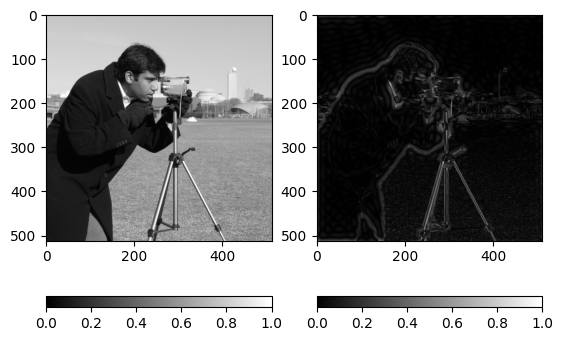

In [20]:
# FFT of image

# Convert image into frequency space
imfft   = fftshift(fft2(im_camera))

# Remove frequencies inside the circular mask
imfft[imw>0]     = 0

#Move low frequencies to the centre
#imf  =  np.abs(ifft2(imfft))

#
imf = np.abs(ifft2(ifftshift(imfft)))

# Plot image

fig  =  plt.figure()
ax  =  fig.add_subplot(1,     2,  1)
plt.imshow(im_camera, cmap='gray')
plt.colorbar(orientation='horizontal')
plt.clim(0,    1)

ax  =  fig.add_subplot(1,     2,  2)
plt.imshow(imf, cmap='gray')
plt.colorbar(orientation='horizontal')
plt.clim(0,    1)


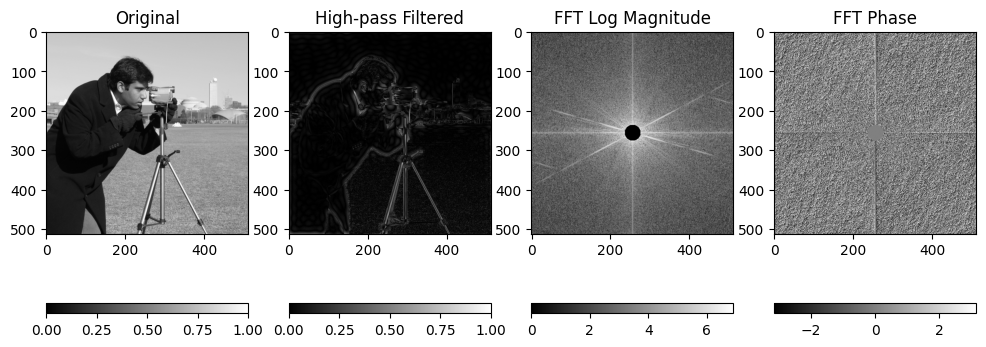

In [25]:
# FFT of image: spatial domain to frequency domain

# Convert image into frequency space
imfft   = fftshift(fft2(im_camera))

# Remove frequencies inside the circular mask
imfft[imw>0]     = 0

# Move low frequencies back? and invert FFT
imf = np.abs(ifft2(ifftshift(imfft)))
imf = np.abs(ifft2(imfft))


# Extract real values and imaginary values
# Use log of absolute value because the dynamic range of magnitude is very large
imm = np.log(1 + np.abs(imfft))
ima = np.angle(imfft)

# Plot image
fig  =  plt.figure(figsize=(12, 6))

ax  =  fig.add_subplot(1,     4,  1)
plt.imshow(im_camera, cmap='gray')
plt.title('Original')
plt.colorbar(orientation='horizontal')
plt.clim(0,    1)

ax  =  fig.add_subplot(1,     4,  2)
plt.imshow(imf, cmap='gray')
plt.title('High-pass Filtered')
plt.colorbar(orientation='horizontal')
plt.clim(0,    1)

ax  =  fig.add_subplot(1,    4,  3)
plt.imshow(imm, cmap='gray')
plt.title('FFT Log Magnitude')
plt.colorbar(orientation='horizontal')

ax  =  fig.add_subplot(1,    4,  4)
plt.imshow(ima, cmap='gray')
plt.title('FFT Phase')
plt.colorbar(orientation='horizontal')

Image shape: (400, 600, 3)


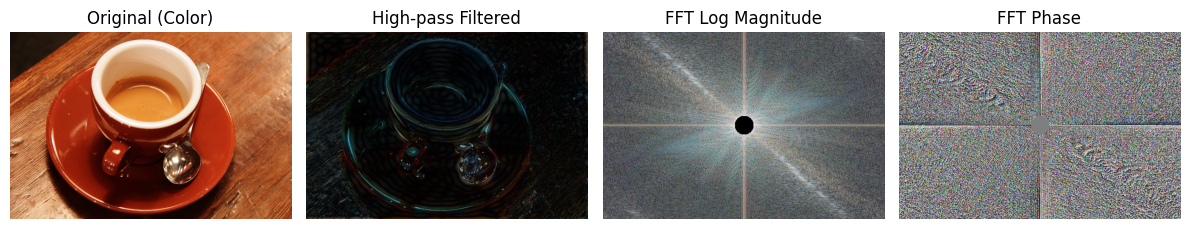

In [28]:
# FFT of image: spatial domain to frequency domain (preserving color channels)

# Keep the image in RGB color space
im_camera = img_as_float(data.coffee())

# create a mask of radius for cutting off low frequencies
r = 20

# The mask coordinates can be calculated using the spatial 2D shape (height, width)
height, width, channels = im_camera.shape
imw = np.zeros((height, width))

# find the mid point
cx, cy = np.round(np.array([height, width])/2)

# create a disk mask
rr, cc = disk((cx, cy), r, shape=imw.shape)
imw[rr, cc] = 1

print("Image shape:", im_camera.shape)

# Process each color channel individually
imf_channels = []
imm_channels = []
ima_channels = []

for i in range(channels):
    channel_data = im_camera[:, :, i]

    # Convert channel into frequency space
    imfft = fftshift(fft2(channel_data))

    # Remove frequencies inside the circular mask
    imfft[imw > 0] = 0

    # Move low frequencies back and invert FFT
    #imf_channel = np.abs(ifft2(ifftshift(imfft)))
    imf_channel = np.abs(ifft2(imfft))


    # Clip values to [0, 1] to avoid plotting artifacts
    imf_channel = np.clip(imf_channel, 0, 1)

    # Extract real values and imaginary values for visualization
    imm_channel = np.log(1 + np.abs(imfft))
    ima_channel = np.angle(imfft)

    imf_channels.append(imf_channel)
    imm_channels.append(imm_channel)
    ima_channels.append(ima_channel)

# Stack the channels back together
imf = np.stack(imf_channels, axis=2)
imm = np.stack(imm_channels, axis=2)
ima = np.stack(ima_channels, axis=2)

# Normalize imm and ima to [0, 1] range for colored visualization
imm_normalized = (imm - imm.min()) / (imm.max() - imm.min())
# Normalize phase (-pi to pi) to [0, 1]
ima_normalized = (ima - ima.min()) / (ima.max() - ima.min())

# Plot image
fig = plt.figure(figsize=(12, 6))

ax = fig.add_subplot(1, 4, 1)
plt.imshow(im_camera)
plt.title('Original (Color)')
plt.axis('off')

ax = fig.add_subplot(1, 4, 2)
plt.imshow(imf)
plt.title('High-pass Filtered')
plt.axis('off')

ax = fig.add_subplot(1, 4, 3)
plt.imshow(imm_normalized)
plt.title('FFT Log Magnitude')
plt.axis('off')

ax = fig.add_subplot(1, 4, 4)
plt.imshow(ima_normalized)
plt.title('FFT Phase')
plt.axis('off')

plt.tight_layout()
plt.show()

In [33]:
import inspect

# source code of numpy's ifftshift function
source_code = inspect.getsource(np.fft.ifftshift)

source_code = inspect.getsource(np.fft.ifftshift)

# Print the source code
print(source_code)

@array_function_dispatch(_fftshift_dispatcher, module='numpy.fft')
def ifftshift(x, axes=None):
    """
    The inverse of `fftshift`. Although identical for even-length `x`, the
    functions differ by one sample for odd-length `x`.

    Parameters
    ----------
    x : array_like
        Input array.
    axes : int or shape tuple, optional
        Axes over which to calculate.  Defaults to None, which shifts all axes.

    Returns
    -------
    y : ndarray
        The shifted array.

    See Also
    --------
    fftshift : Shift zero-frequency component to the center of the spectrum.

    Examples
    --------
    >>> import numpy as np
    >>> freqs = np.fft.fftfreq(9, d=1./9).reshape(3, 3)
    >>> freqs
    array([[ 0.,  1.,  2.],
           [ 3.,  4., -4.],
           [-3., -2., -1.]])
    >>> np.fft.ifftshift(np.fft.fftshift(freqs))
    array([[ 0.,  1.,  2.],
           [ 3.,  4., -4.],
           [-3., -2., -1.]])

    """
    x = asarray(x)
    if axes is None:
        axe

## 2 Visualization

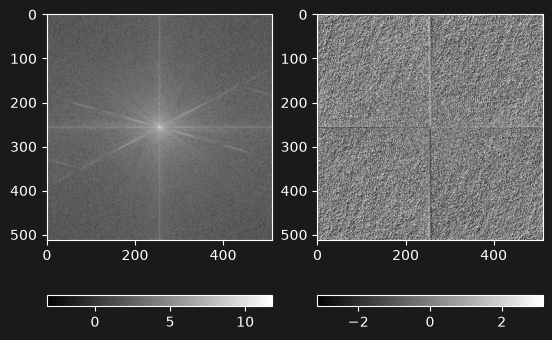

In [ ]:
imm  =  np.log(np.abs(imfft))
ima  =  np.angle(imfft)


fig  =  plt.figure()

ax  =  fig.add_subplot(1,     2,  1)
p  = plt.imshow(imm, cmap='gray')
c  = plt.colorbar(orientation='horizontal')

ax  =  fig.add_subplot(1,     2,  2)
p  = plt.imshow(ima, cmap='gray')
c  = plt.colorbar(orientation='horizontal')


## 3 Frequency Components


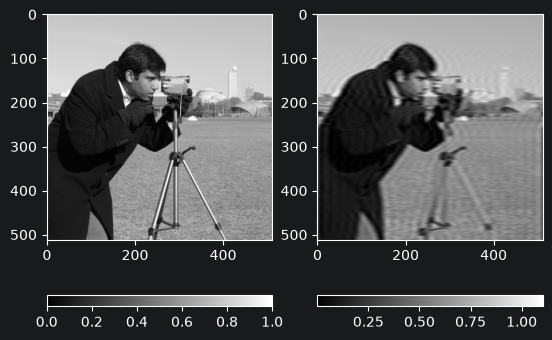

In [ ]:
im  = img_as_float(data.camera())
imfft   = fftshift(fft2(im))
cx, cy   = np.round(np.array(im.shape)/2)
rx  = np.round(np.array(im.shape[0])/2)
ry  = np.round(np.array(im.shape[1])/20)
rot  =  np.deg2rad(0)
rr, cc   = ellipse(cx, cy, rx, ry, rotation=rot)
imw  =  np.zeros_like(im)
imw[rr, cc]    =  1
imfft[imw==0]     = 0
imf  =  np.abs(ifft2(imfft))
fig  =  plt.figure()
ax  = fig.add_subplot(1,      2,  1)
p  = plt.imshow(im, cmap='gray')
c  = plt.colorbar(orientation='horizontal')
ax  = fig.add_subplot(1,      2,  2)
p  = plt.imshow(imf, cmap='gray')
c  = plt.colorbar(orientation='horizontal')


## 3 Frequency Components


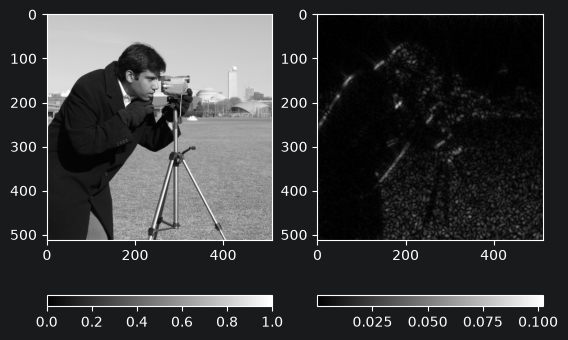

In [ ]:
imfft   = fftshift(fft2(im))
cx, cy   =  np.round(np.array(im.shape)/4)
r  = np.round(np.array(im.shape[1])/10)
rr, cc   =  disk((cx, cy), r, shape=im.shape)
imw  =  np.zeros_like(im)
imw[rr, cc]    =  1
rr, cc   =  disk((3*cx,    3*cy), r, shape=im.shape)
imw[rr, cc]    =  1
imfft[imw==0]     = 0
imf  =  np.abs(ifft2(imfft))
fig  =  plt.figure()
ax  =  fig.add_subplot(1,     2,  1)
p  = plt.imshow(im, cmap='gray')
c  = plt.colorbar(orientation='horizontal')
ax  =  fig.add_subplot(1,     2,  2)
p  = plt.imshow(imf, cmap='gray')
c  = plt.colorbar(orientation='horizontal')


## 3 Frequency Components


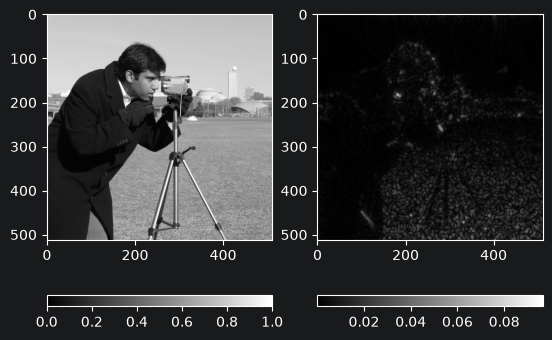

In [ ]:
imfft   = fftshift(fft2(im))
cx, cy   =  np.round(np.array(im.shape)/4)
r  = np.round(np.array(im.shape[1])/10)
rr, cc   =  disk((3*cx, cy), r, shape=im.shape)
imw  =  np.zeros_like(im)
imw[rr, cc]    =  1
rr, cc   =  disk((cx,   3*cy), r, shape=im.shape)
imw[rr, cc]    =  1
imfft[imw==0]     = 0
imf  =  np.abs(ifft2(imfft))
fig  =  plt.figure()
ax  =  fig.add_subplot(1,     2,  1)
p  = plt.imshow(im, cmap='gray')
c  = plt.colorbar(orientation='horizontal')
ax  =  fig.add_subplot(1,     2,  2)
p  = plt.imshow(imf, cmap='gray')
c  = plt.colorbar(orientation='horizontal')


## # Low -frequencies


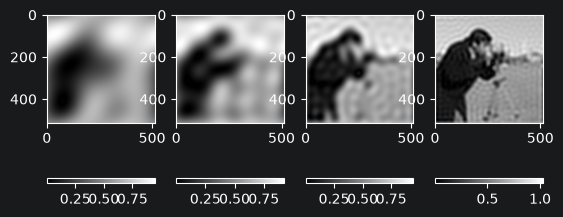

In [ ]:
im  =  img_as_float(data.camera())
fig  =  plt.figure()
r  = np.array([3,     5,  10,  20])
for  i  in  range(0, r.shape[0]):
   imw  = np.zeros_like(im)
   cx, cy   = np.round(np.array(im.shape)/2)
   rr, cc   = disk((cx, cy), r[i], shape=im.shape)
   imw[rr, cc]    =  1
   imfft  =  fftshift(fft2(im))
   imfft[imw==0]     = 0
   imf  = np.abs(ifft2(imfft))
   ax  = fig.add_subplot(1, r.shape[0], i+1)
   p =  plt.imshow(imf, cmap='gray')
   c =  plt.colorbar(orientation='horizontal')


## 4 High -frequencies


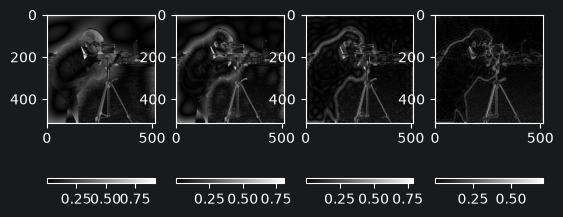

In [ ]:
im  =  img_as_float(data.camera())
fig  =  plt.figure()
r  = np.array([3,     5, 10,  20])
for  i  in  range(0, r.shape[0]):
   imw  = np.zeros_like(im)
   cx, cy   = np.round(np.array(im.shape)/2)
   rr, cc   = disk((cx, cy), r[i], shape=im.shape)
   imw[rr, cc]    = 1
   imfft  =  fftshift(fft2(im))
   imfft[imw==1]    =  0
   imf  = np.abs(ifft2(imfft))
   ax  = fig.add_subplot(1, r.shape[0], i+1)
   p =  plt.imshow(imf, cmap='gray')
   c =  plt.colorbar(orientation='horizontal')


## 5 DTF Example


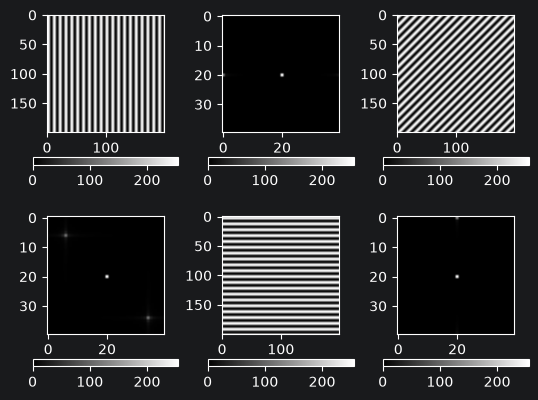

In [ ]:
def  normalize(x):
   return  (x  -  x.min())   / (x.max()    - x.min())
im  = img_as_float(data.camera())
xs  = np.linspace(-2*np.pi,       2*np.pi,   200)
ys  = np.linspace(-2*np.pi,       2*np.pi,   200)
fig  =  plt.figure()
a  = np.array([0,    45,  90])
a  = np.deg2rad(a)
for  i  in range(0,a.shape[0]):
   x, y  = np.meshgrid(xs, ys)
   x =  x *  np.cos(a[i])    + y  * np.sin(a[i])
   y =  -x *  np.sin(a[i])    +  y *  np.cos(a[i])
   f =  10
   imp  = np.sin(f*x)
   imp  = normalize(imp+np.abs(imp.min()))
   imfft  =  fftshift(fft2(imp))
   imm  = np.abs(imfft)
   imp  = img_as_ubyte(normalize(imp))
   imm  = img_as_ubyte(normalize(imm))
   ax =  fig.add_subplot(2, a.shape[0], (2*i)+1)
   p =  plt.imshow(imp, cmap='gray')
   c =  plt.colorbar(orientation='horizontal')
   ax =  fig.add_subplot(2, a.shape[0], (2*i)+2)
   p =  plt.imshow(imm[80:120,      80:120], cmap='gray')
   c =  plt.colorbar(orientation='horizontal')


## 6 DTF Example - 2


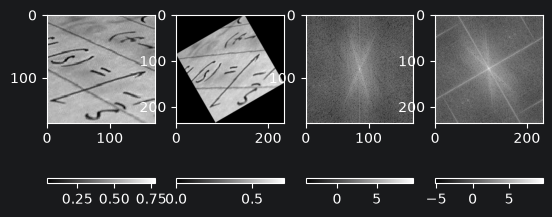

In [ ]:
im  =  img_as_float(data.text())
im  =  im[0:172,   0:172]
imr  =  rotate(im,    30, resize=True)
imfft   = fftshift(fft2(im))
imm  =  np.log(np.abs(imfft))
imrfft   =  fftshift(fft2(imr))
imrm   = np.log(np.abs(imrfft))
fig  =  plt.figure()
ax  =  fig.add_subplot(1,     4,  1)
p  = plt.imshow(im, cmap='gray')
c  = plt.colorbar(orientation='horizontal')
ax  =  fig.add_subplot(1,     4,  2)
p  = plt.imshow(imr, cmap='gray')
c  = plt.colorbar(orientation='horizontal')
ax  =  fig.add_subplot(1,     4,  3)
p =  plt.imshow(imm, cmap='gray')
c =  plt.colorbar(orientation='horizontal')
ax =  fig.add_subplot(1,      4, 4)
p =  plt.imshow(imrm, cmap='gray')
c =  plt.colorbar(orientation='horizontal')
